In [5]:
from sound_simulation import *
from beamforming import *
from sensor_array import *
from scene import *
from util import *
from psd_estimation import *
from plot_utils import *
from cropac import *

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import display, clear_output, Audio

In [6]:
fig_width = 11

duration = 5
sr = 48000
c = 344
fmin = 500
fmax = 6000

sensor_array = array_circle8()
noise = prepare_audio("../samples/meas1_ambience.wav", duration, sr, False)
noise *= sensor_array.calibration[:,None]

target_position = np.array([50, 0, 10])
scene = scene_stationary(duration, sr, target_position)
target_sound = prepare_drone_audio(scene, sensor_array, "../samples/mavic4_flight.wav", duration, sr, db2lin(65-60))

audio = noise + target_sound

N = 2**10
step = N//2
window = np.hanning(N)**0.5
VN, f, validf = valid_frequency_bins(fmin, fmax, N, sr)
SN, tidx, snaps = stft(audio, window, step, validf)
_, _, target_snaps = stft(target_sound, window, step, validf)
k = 2 * np.pi * f / c

target_udir = target_position / np.linalg.norm(target_position)
target_steer = create_steering_vectors(create_distance_vectors(target_udir[None,:], sensor_array.positions), k[:,None])

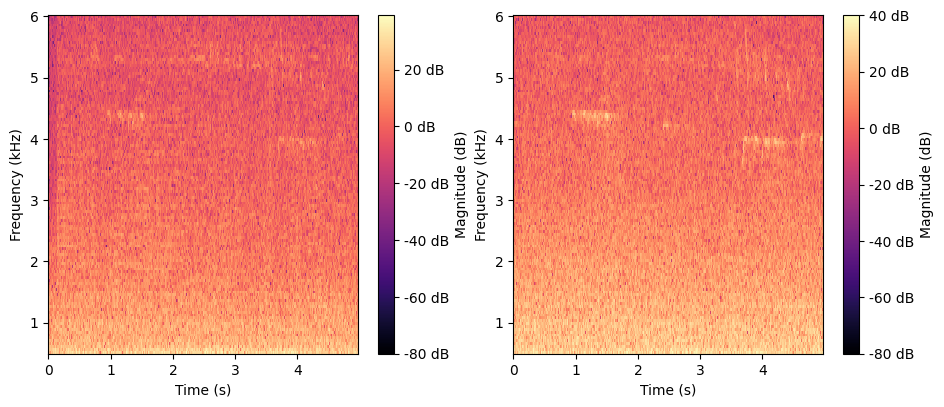

In [7]:


w_das = wideband_das_weights(target_steer)
filtered_snaps = np.array([beamform_wideband(s.T, w_das) for s in snaps])

sdas = istft(filtered_snaps, window, tidx, validf)
ch0 = istft(snaps[:,0,:], window, tidx, validf)

display(Audio(sdas, rate=sr))
display(Audio(ch0, rate=sr))

fig = plt.figure(figsize=(fig_width, fig_width*0.4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
plot_spectrogram(ax1, f, tidx/sr, lin2db(filtered_snaps).T)
plot_spectrogram(ax2, f, tidx/sr, lin2db(snaps[:,0,:]).T)

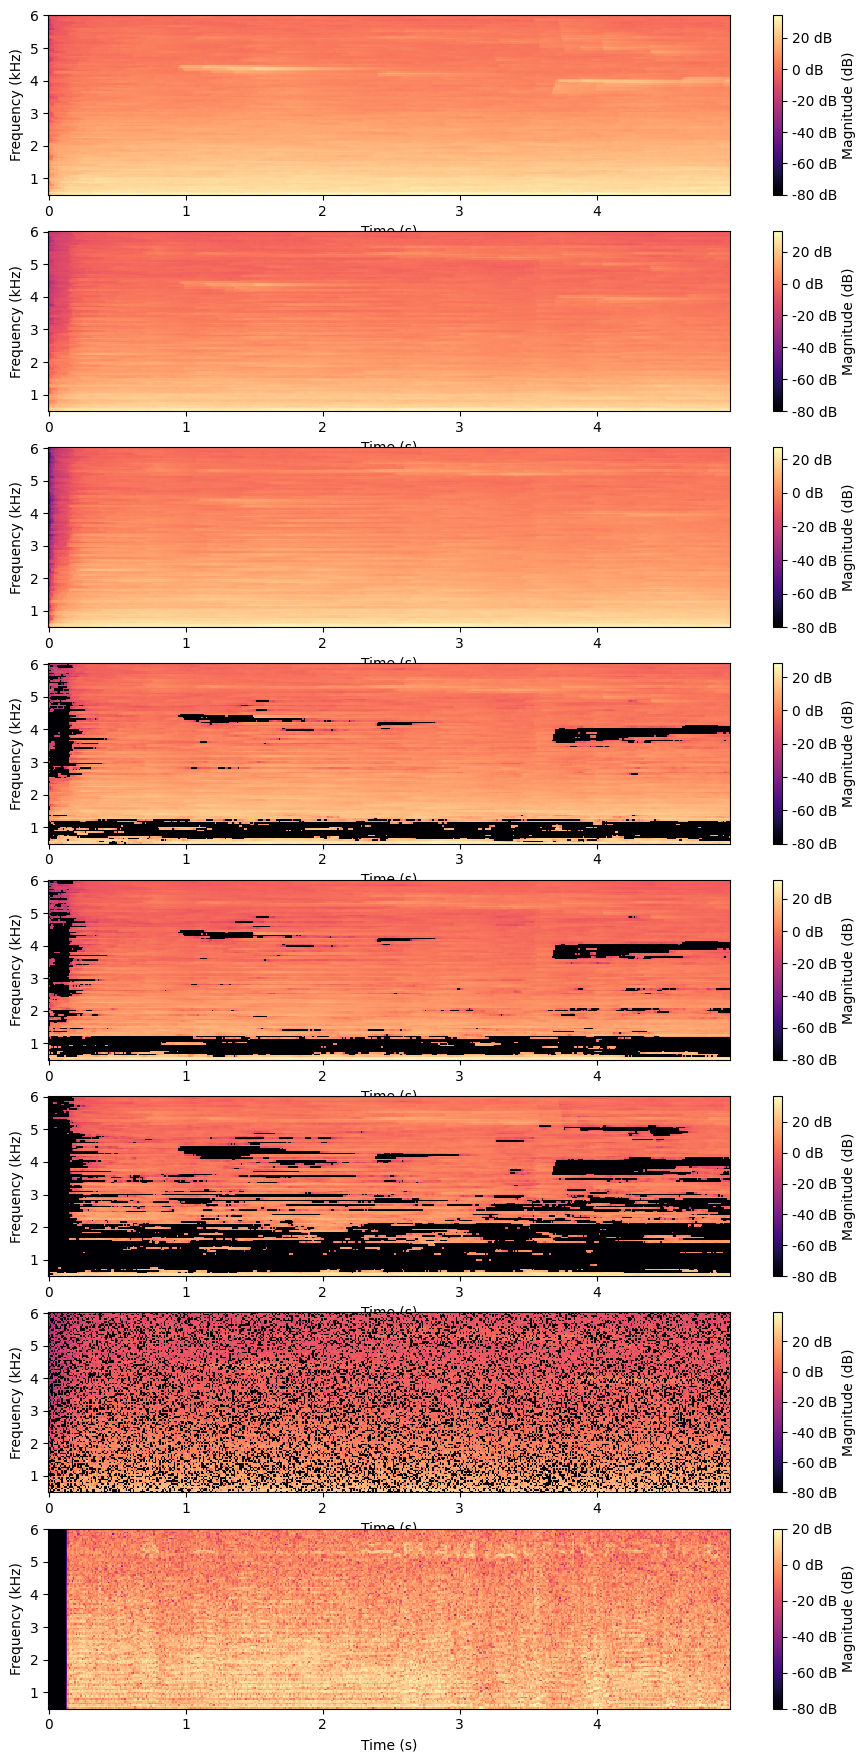

In [9]:
params = PSDEParams(
    sensor_array.positions,
    target_udir, k,
    target_steer,
    compute_covariance_matrices(snaps[0]))
das_estimator = DAS_PSDE(params)
ch0_estimator = CH0_PSDE(params)
mvdr_estimator = MVDR_PSDE(params, db2lin(-10))
cropac_estimator = CroPaC_PSDE(params)
dobec_estimator = DOBEC_PSDE(params)
nobec_estimator = NOBEC_PSDE(params, db2lin(0))
dmvdr_estimator = DMVDR_PSDE(params, db2lin(0))

Sx = np.array([compute_covariance_matrices(snap) for snap in snaps])
Sx = time_average(Sx, smoothing_alpha(sr*0.125, step, 0.5))

das_psd = np.array([das_estimator.estimate_psd(s) for s in Sx])
ch0_psd = np.array([ch0_estimator.estimate_psd(s) for s in Sx])
mvdr_psd = np.array([mvdr_estimator.update_and_estimate(params, s) for s in Sx])
cropac_psd = np.array([cropac_estimator.estimate_psd(s) for s in Sx])
dobec_psd = np.array([dobec_estimator.estimate_psd(s) for s in Sx])
nobec_psd = np.array([nobec_estimator.update_and_estimate(params, s) for s in Sx])
dmvdr_psd = np.array([dmvdr_estimator.update_and_estimate(params, s) for s in Sx])
# nobec_psd = time_average(nobec_psd, smoothing_alpha(sr*0.05, step, 0.5))

St = np.array([compute_covariance_matrices(snap) for snap in target_snaps])
target_psd = np.array([das_estimator.estimate_psd(s) for s in St])

psdas = psd_to_sound(das_psd, window, tidx, validf)
psch0 = psd_to_sound(ch0_psd, window, tidx, validf)
psa = psd_to_sound(nobec_psd, window, tidx, validf)
display(Audio(psch0, rate=sr))
display(Audio(psdas, rate=sr))
display(Audio(psa, rate=sr))

fig = plt.figure(figsize=(fig_width, fig_width*2))
ax1 = fig.add_subplot(811)
ax2 = fig.add_subplot(812)
ax3 = fig.add_subplot(813)
ax4 = fig.add_subplot(814)
ax5 = fig.add_subplot(815)
ax6 = fig.add_subplot(816)
ax7 = fig.add_subplot(817)
ax8 = fig.add_subplot(818)
plot_spectrogram(ax1, f, tidx/sr, pow2db(ch0_psd).T)
plot_spectrogram(ax2, f, tidx/sr, pow2db(das_psd).T)
plot_spectrogram(ax3, f, tidx/sr, pow2db(mvdr_psd).T)
plot_spectrogram(ax4, f, tidx/sr, pow2db(cropac_psd).T)
plot_spectrogram(ax5, f, tidx/sr, pow2db(dobec_psd).T)
plot_spectrogram(ax6, f, tidx/sr, pow2db(nobec_psd*10).T)
plot_spectrogram(ax7, f, tidx/sr, pow2db(dmvdr_psd).T)
plot_spectrogram(ax8, f, tidx/sr, pow2db(target_psd).T)